# 🐾 Project 2: Multi-task Deep Learning on The Oxford-IIIT Pet Dataset
**รายวิชา:** Deep Learning for Image Analysis  
**หัวข้อโครงงาน:** การเรียนรู้แบบหลายงานร่วมกัน (Multi-task Learning) สำหรับการตัดขอบภาพสัตว์เลี้ยงระดับพิกเซล (Semantic Segmentation) และการจำแนกสายพันธุ์สัตว์เลี้ยง (Fine-grained Breed & Species Classification)  

---

## 📌 คำแนะนำสำหรับทีมทำสไลด์นำเสนอ (Slide Deck Guide)
สมุดบันทึก (`.ipynb`) ไฟล์นี้ถูกจัดทำขึ้นเพื่อให้สมาชิกในกลุ่มสามารถดึง **ข้อมูลตัวเลข, ตารางเปรียบเทียบ, กราฟ Confusion Matrix, ภาพตัวอย่างการทำนาย (Good / Error Cases) และคำอธิบายเชิงเทคนิค** ไปใส่ในสไลด์ได้ทันที โดยแบ่งหัวข้อตรงตามเกณฑ์การให้คะแนนเต็ม **15 คะแนน** ของอาจารย์ทุกข้อ:

1. **ความยากของงาน (4 คะแนน):** อธิบายโครงสร้างแบบจำลอง Multi-task Learning ที่ใช้ Shared Backbone เรียนรู้ร่วมกันพร้อมกัน 3 งานย่อย (Segmentation + 37-Breed Cls + Cat/Dog Cls)
2. **การกำหนดปัญหาและเตรียมข้อมูล (2 คะแนน):** ระบุแหล่งข้อมูล Oxford VGG, สัดส่วนการแบ่งข้อมูล (Train 2,944 / Val 736 / Test 3,669) และกลไกป้องกัน Data Leakage
3. **การพัฒนาแบบจำลองและการทดลอง (2 คะแนน):** อธิบายสถาปัตยกรรม U-Net + ResNet, ฟังก์ชันสูญเสีย (Joint Loss), การตั้งค่า Hyperparameters และการเปรียบเทียบ 3 รูปแบบด้วยการปรับน้ำหนัก Loss ระหว่างงาน
4. **การประเมินและวิเคราะห์ผล (2 คะแนน):** รายงานตัวชี้วัดแยกแต่ละงาน (mIoU, Dice Score, IoU รายคลาส, Precision, Recall, Macro F1, Accuracy) บน Unseen Test Set พร้อมวิเคราะห์เคสที่ทำนายถูก/ผิด และข้อจำกัด
5. **ความสวยงามของสื่อ (2 คะแนน) และการนำเสนอ/ตอบคำถาม (3 คะแนน):** มีโค้ดสร้างกราฟความละเอียดสูง (300 DPI) สำหรับนำไปวางในสไลด์ได้ทันที

---
## ส่วนที่ 1: การกำหนดปัญหาและการเตรียมข้อมูล (2 คะแนน)
*(เนื้อหาสำหรับสไลด์แผ่นที่ 2 - 3)*

### 1.1 ที่มาและวัตถุประสงค์ของปัญหา (Problem Statement & Objectives)
ในการวิเคราะห์ภาพสัตว์เลี้ยงหรือภาพทางการแพทย์ การจำแนกเพียงว่าวัตถุในภาพคือคลาสใด (Classification) มักไม่เพียงพอต่อการนำไปใช้งานจริงที่ต้องการทราบตำแหน่งและขอบเขตระดับพิกเซล (Segmentation) หากแยกสร้าง 2 โมเดลทำงานต่อกัน (Sequential Pipeline) จะสิ้นเปลืองหน่วยความจำและเวลาประมวลผลถึง 2 เท่า  

**วัตถุประสงค์ของโครงงาน:**
1. พัฒนาโมเดล **Multi-task Deep Learning (Hard Parameter Sharing)** เพียงโมเดลเดียวที่เรียนรู้ร่วมกันพร้อมกันทั้ง 2 งานหลัก:
   - **Task 1 (Image Segmentation):** แยกส่วนสัตว์เลี้ยง (Foreground), พื้นหลัง (Background), และเส้นขอบเขต (Boundary/Trimap) ในระดับพิกเซล
   - **Task 2 (Image Classification):** จำแนกสายพันธุ์สัตว์เลี้ยงแบบละเอียด (Fine-grained 37 สายพันธุ์) และจำแนกประเภทสัตว์ (Cat vs. Dog)
2. ศึกษาผลของการถ่วงน้ำหนัก Loss ระหว่างงาน ($\lambda_{seg}$ : $\lambda_{breed}$) ว่าการเน้นงานหนึ่งส่งผลต่ออีกงานอย่างไร (Task Trade-off) โดยเปรียบเทียบ 3 รูปแบบ
3. ประเมินผลแยกแต่ละงานบน Unseen Test Set พร้อมวิเคราะห์ตัวอย่างที่ถูก/ผิดและข้อจำกัด

### 1.2 แหล่งข้อมูลและสถิติชุดข้อมูล (Dataset Statistics)
* **ชื่อชุดข้อมูล:** The Oxford-IIIT Pet Dataset (จากกลุ่มวิจัย Visual Geometry Group - VGG, University of Oxford)
* **จำนวนภาพทั้งหมด:** 7,349 ภาพ
* **จำนวนคลาสสายพันธุ์:** 37 สายพันธุ์ (แบ่งเป็น สุนัข 25 สายพันธุ์ จำนวน 4,978 ภาพ และ แมว 12 สายพันธุ์ จำนวน 2,371 ภาพ)
* **ป้ายกำกับ (Annotations):** ทุกภาพมีป้ายกำกับระดับภาพ (Breed & Species) และป้ายกำกับระดับพิกเซลแบบ Trimap (Foreground, Background, Boundary)

### 1.3 กลยุทธ์การแบ่งข้อมูลและการป้องกัน Data Leakage (Data Splitting & Leakage Prevention)
เพื่อความโปร่งใสและป้องกันข้อมูลรั่วไหล (Data Leakage) อย่างเคร่งครัด โครงงานนี้จัดการข้อมูลดังนี้:
1. **แยกชุดทดสอบ (Unseen Test Set) เด็ดขาด:** ใช้การแบ่ง Official Benchmark ของ Oxford โดยล็อกชุด `test` จำนวน **3,669 ภาพ (50%)** แยกไว้ต่างหาก ไม่นำมาใช้ในการอัปเดตพารามิเตอร์หรือเลือก checkpoint (ใช้รายงานผลเท่านั้น)
2. **การแบ่งชุดฝึกสอนและตรวจสอบ (Stratified Train/Val Split):** นำชุด `trainval` จำนวน **3,680 ภาพ** มาแบ่งด้วยวิธี **Stratified Shuffle Split (80:20)** โดยยึดตามสัดส่วนสายพันธุ์ทั้ง 37 คลาส เพื่อให้ทุกสายพันธุ์กระจายตัวเท่ากัน:
   - **Training Set:** 2,944 ภาพ (ใช้ฝึกสอนโมเดล)
   - **Validation Set:** 736 ภาพ (ใช้ตรวจสอบระหว่างเทรนและเลือก Best Checkpoint ด้วยคะแนน (mIoU + Breed Macro F1) / 2)
   - **Unseen Test Set:** 3,669 ภาพ (ใช้ประเมินผลลัพธ์สุดท้ายเพียงครั้งเดียว)
3. **การแยก Pipeline ของ Data Augmentation:** การพลิกภาพ (Random Flip), การหมุนภาพ (Random Rotation $\pm 10^\circ$), และการปรับสี (Color Jitter) ทำ **เฉพาะในชุด Training เท่านั้น** และทำแบบ Synchronized (หมุนภาพและ Mask ด้วยมุมเดียวกันเป๊ะ) ส่วนชุด Validation และ Test ทำเพียงการ Resize ($224 \times 224$) และ Normalize ด้วยค่าสถิติของ ImageNet เท่านั้น

In [1]:
# เซลล์ที่ 1: โหลดไลบรารีและตรวจสอบการตั้งค่าของโปรเจกต์
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from configs.config import Config
from data.dataset import get_dataloaders
from data.class_mappings import BREED_NAMES, CAT_BREEDS, get_species_id
from models.multitask_model import MultiTaskResNet
from utils.metrics import compute_segmentation_metrics, compute_classification_metrics

# ตั้งค่ารูปแบบกราฟให้สวยงามสำหรับนำไปใส่สไลด์
plt.rcParams['figure.dpi'] = 150
plt.rcParams['savefig.dpi'] = 300
sns.set_theme(style="whitegrid")

cfg = Config()
print(f"[+] อุปกรณ์ประมวลผล: {cfg.DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print(f"[+] ขนาดภาพ Input: {cfg.IMAGE_SIZE}x{cfg.IMAGE_SIZE}")
print(f"[+] จำนวนคลาส: Segmentation={cfg.NUM_CLASSES_SEG} คลาส | Breed={cfg.NUM_CLASSES_BREED} สายพันธุ์ | Species={cfg.NUM_CLASSES_SPECIES} ประเภท")

[+] อุปกรณ์ประมวลผล: cuda (NVIDIA GeForce RTX 4050 Laptop GPU)
[+] ขนาดภาพ Input: 224x224
[+] จำนวนคลาส: Segmentation=3 คลาส | Breed=37 สายพันธุ์ | Species=2 ประเภท


,ชุดข้อมูล (Dataset Split),จำนวนภาพ (Images),สัดส่วน (%),การทำ Augmentation
0,Training Set,2944,40.1%,"ทำ (Flip, Rotate, ColorJitter)"
1,Validation Set,736,10.0%,ไม่ทำ (Resize + Normalize เท่านั้น)
2,Unseen Test Set,3669,49.9%,ไม่ทำ (Resize + Normalize เท่านั้น)
3,รวมทั้งหมด (Total),7349,100.0%,-


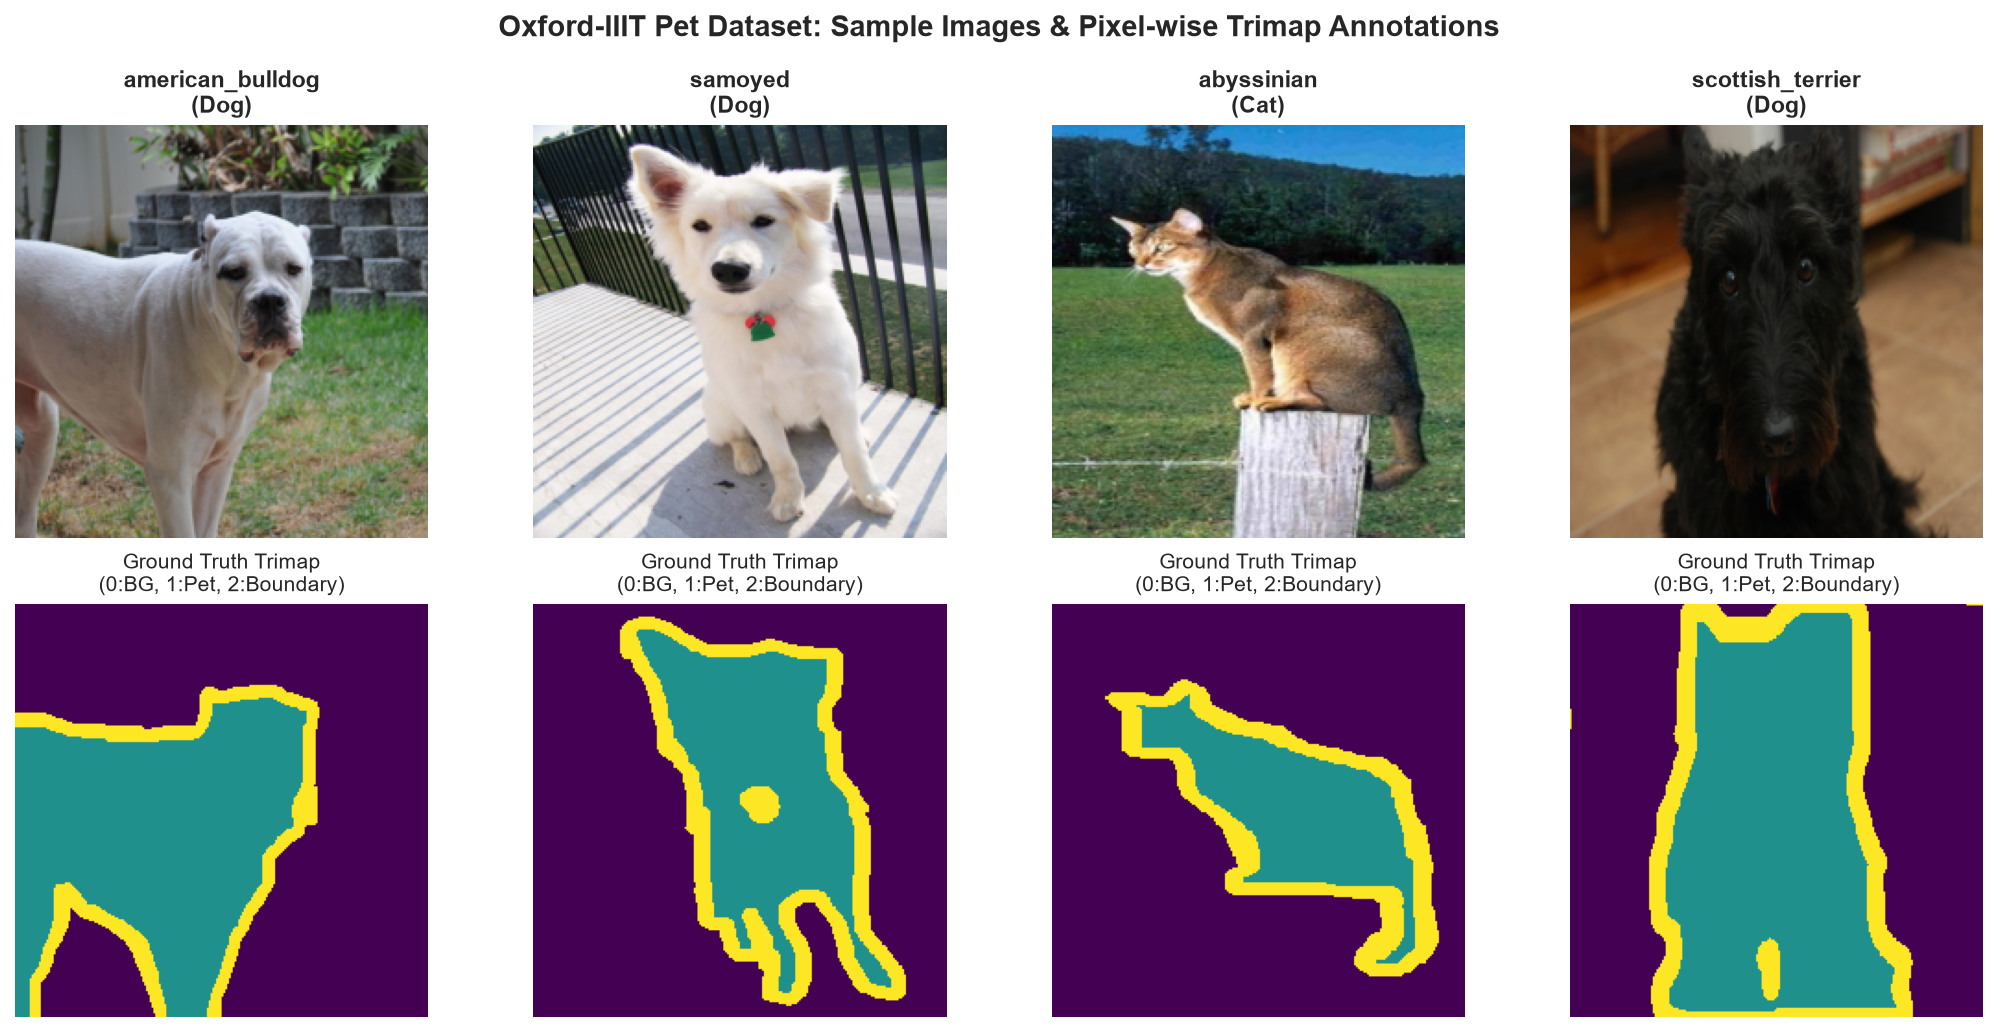

In [2]:
# เซลล์ที่ 2: ตรวจสอบขนาดของชุดข้อมูล Train / Validation / Test และแสดงตัวอย่างภาพพร้อม Ground Truth Mask
train_loader, val_loader, test_loader = get_dataloaders(cfg)

n_train = len(train_loader.dataset)
n_val = len(val_loader.dataset)
n_test = len(test_loader.dataset)
n_total = n_train + n_val + n_test

split_df = pd.DataFrame({
    "ชุดข้อมูล (Dataset Split)": ["Training Set", "Validation Set", "Unseen Test Set", "รวมทั้งหมด (Total)"],
    "จำนวนภาพ (Images)": [n_train, n_val, n_test, n_total],
    "สัดส่วน (%)": [f"{n_train/n_total*100:.1f}%", f"{n_val/n_total*100:.1f}%", f"{n_test/n_total*100:.1f}%", "100.0%"],
    "การทำ Augmentation": ["ทำ (Flip, Rotate, ColorJitter)", "ไม่ทำ (Resize + Normalize เท่านั้น)", "ไม่ทำ (Resize + Normalize เท่านั้น)", "-"]
})
display(split_df)

# แสดงภาพตัวอย่างจากชุดข้อมูล (ใช้หัวข้อภาษาอังกฤษเพื่อความคมชัดและไม่เพี้ยน)
sample_batch = next(iter(val_loader))
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i in range(4):
    img = sample_batch["image"][i].permute(1, 2, 0).numpy()
    img = np.clip(img * std + mean, 0, 1)
    mask = sample_batch["mask"][i].numpy()
    breed_name = BREED_NAMES[sample_batch["breed"][i].item()]
    species_name = "Cat" if sample_batch["species"][i].item() == 0 else "Dog"
    
    axes[0, i].imshow(img)
    axes[0, i].set_title(f"{breed_name}\n({species_name})", fontsize=11, fontweight="bold")
    axes[0, i].axis("off")
    
    axes[1, i].imshow(mask, cmap="viridis", vmin=0, vmax=2)
    axes[1, i].set_title("Ground Truth Trimap\n(0:BG, 1:Pet, 2:Boundary)", fontsize=10)
    axes[1, i].axis("off")

plt.suptitle("Oxford-IIIT Pet Dataset: Sample Images & Pixel-wise Trimap Annotations", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(cfg.OUTPUT_DIR, "slide_dataset_samples.png"), dpi=300)
plt.show()

---
## ส่วนที่ 2: สถาปัตยกรรมแบบจำลองและการตั้งค่าการทดลอง (4 + 2 คะแนน)
*(เนื้อหาสำหรับสไลด์แผ่นที่ 4 - 6: อธิบายความยากระดับ Multi-task 4 คะแนน และการทดลองเปรียบเทียบ 2 คะแนน)*

### 2.1 สถาปัตยกรรมแบบจำลอง Multi-task Learning (Hard Parameter Sharing)
แบบจำลองประกอบด้วย 3 ส่วนหลักที่เชื่อมต่อและฝึกสอนไปพร้อมกัน (End-to-End Joint Training):

```text
                       ┌───> [U-Net Decoder + Skip Connections (C1..C4)] ───> Segmentation Mask (3 Classes: BG, Pet, Boundary)
                       │
Input Image (224x224) ─┴───> [Shared ResNet Backbone (C1..C5)] 
                       │
                       └───> [Global Avg Pooling + Dropout (C5)] ─┬─> [Breed MLP Head]   ───> 37 Pet Breeds
                                                                  └─> [Species MLP Head] ───> 2 Species (Cat / Dog)
```

1. **Shared Encoder Backbone:** ใช้โครงข่าย ResNet-50 ที่ผ่านการ Pre-train บน ImageNet สกัดแผนที่คุณลักษณะ (Feature Maps) 5 ระดับความละเอียด ได้แก่ $C_1 (H/2), C_2 (H/4), C_3 (H/8), C_4 (H/16)$ และ $C_5 (H/32)$
2. **Segmentation Branch (U-Net Style Decoder):** นำฟีเจอร์ระดับลึกสุด $C_5$ มาขยายขนาดภาพกลับ (Transposed Convolution Upsampling) พร้อมนำฟีเจอร์ระดับตื้น $C_4, C_3, C_2, C_1$ มาเชื่อมต่อข้ามชั้น (**Skip Connections**) เพื่อรักษาความคมชัดของเส้นขนและขอบตัวสัตว์ ก่อนทำนายออกเป็น 3 คลาสต่อพิกเซล
3. **Classification Branches:** นำฟีเจอร์ระดับลึกสุด $C_5$ มาผ่าน Global Average Pooling (GAP) และ Dropout ($p=0.3$) แล้วแยกเข้าสู่ 2 หัวทำนาย:
   - **Breed Classification Head:** `Linear(2048 -> 512) -> ReLU -> Dropout(0.2) -> Linear(512 -> 37)`
   - **Species Classification Head:** `Linear(2048 -> 128) -> ReLU -> Linear(128 -> 2)`

### 2.2 ฟังก์ชันการสูญเสียร่วม (Multi-task Joint Loss Function)
แบบจำลองเรียนรู้ร่วมกันด้วยการรวม Loss ของทุกงานเข้าด้วยกัน:
$$\mathcal{L}_{total} = \lambda_{seg} \left( \mathcal{L}_{CE\_seg} + \mathcal{L}_{Dice} \right) + \lambda_{breed} \mathcal{L}_{CE\_breed} + \lambda_{species} \mathcal{L}_{CE\_species}$$
* $\mathcal{L}_{seg}$: ใช้ผลรวมของ **Cross-Entropy Loss** และ **Multi-class Dice Loss** เพื่อแก้ปัญหาพื้นที่เส้นขอบ (Boundary) มีจำนวนพิกเซลน้อยกว่าพื้นหลัง
* $\mathcal{L}_{CE\_breed}$: ใช้ Cross-Entropy Loss พร้อม **Label Smoothing ($0.05$)** เพื่อป้องกัน Overfitting ในการจำแนก 37 สายพันธุ์
* ค่าน้ำหนักตั้งต้น: $\lambda_{seg} = 1.0, \lambda_{breed} = 1.0, \lambda_{species} = 0.5$

### 2.3 การตั้งค่าการฝึกสอนและการทดลองเปรียบเทียบ 3 รูปแบบ (Experimental Setup)
* **Optimizer:** AdamW (`lr = 1e-4`, `weight_decay = 1e-4`)
* **LR Scheduler:** Cosine Annealing LR ลดค่า Learning Rate ลงจนถึง `1e-6` ที่ Epoch สุดท้าย
* **Epochs & Batch Size:** 30 Epochs, Batch Size = 32 (ค่าที่ `configs/config.py` ใช้จริง — ตรวจสอบได้จากตาราง Hyperparameter ในเซลล์ที่ 5), Mixed Precision `bfloat16`
* **การเลือก Checkpoint:** บันทึก epoch ที่คะแนน (mIoU + Breed Macro F1) / 2 บน **Validation Set** สูงสุด
* **รูปแบบที่เปรียบเทียบอย่างเป็นธรรม (3 รูปแบบ):** ทั้ง 3 รูปแบบเป็น Multi-task ResNet-50 สถาปัตยกรรมเดียวกัน ใช้ข้อมูล split เดียวกัน (seed 42), augmentation, ขนาดภาพ, optimizer, learning rate และจำนวน epoch เท่ากัน **ต่างกันเพียงน้ำหนัก Loss**:

  | รูปแบบ | $\lambda_{seg}$ | $\lambda_{breed}$ | $\lambda_{species}$ | คำสั่งเทรน |
  |---|:---:|:---:|:---:|---|
  | **Balanced (โมเดลหลัก)** | 1.0 | 1.0 | 0.5 | `python train.py` |
  | Seg-focused | 2.0 | 0.5 | 0.5 | `python train.py --w_seg 2.0 --w_breed 0.5` |
  | Cls-focused | 0.5 | 2.0 | 0.5 | `python train.py --w_seg 0.5 --w_breed 2.0` |

  **Balanced** เป็นการตั้งค่าหลักที่กำหนดไว้ตั้งแต่ต้น (ค่า default ใน `configs/config.py`) และเป็นโมเดลที่ใช้ใน `evaluate.py` / `inference.py` ส่วนอีก 2 รูปแบบใช้ศึกษาว่าการเน้นงานใดงานหนึ่งส่งผลต่ออีกงานอย่างไร


In [3]:
# เซลล์ที่ 3: ตรวจสอบจำนวนพารามิเตอร์ของโมเดล (Model Complexity Summary)
model = MultiTaskResNet(cfg).to(cfg.DEVICE)

total_params = sum(p.numel() for p in model.parameters())
backbone_params = sum(p.numel() for p in model.backbone.parameters())
decoder_params = sum(p.numel() for p in model.decoder.parameters())
cls_params = sum(p.numel() for p in model.breed_head.parameters()) + sum(p.numel() for p in model.species_head.parameters())

param_df = pd.DataFrame({
    "ส่วนประกอบของโมเดล (Module)": [
        f"Shared Backbone ({cfg.BACKBONE})",
        "Segmentation Decoder (U-Net Style)",
        "Classification Heads (Breed + Species)",
        "รวมพารามิเตอร์ทั้งหมด (Total Parameters)"
    ],
    "จำนวนพารามิเตอร์ (Parameters)": [
        f"{backbone_params:,}",
        f"{decoder_params:,}",
        f"{cls_params:,}",
        f"{total_params:,}"
    ],
    "สัดส่วน (%)": [
        f"{backbone_params/total_params*100:.1f}%",
        f"{decoder_params/total_params*100:.1f}%",
        f"{cls_params/total_params*100:.1f}%",
        "100.0%"
    ]
})
display(param_df)

,ส่วนประกอบของโมเดล (Module),จำนวนพารามิเตอร์ (Parameters),สัดส่วน (%)
0,Shared Backbone (resnet50),"23,508,032",48.2%
1,Segmentation Decoder (U-Net Style),"23,965,123",49.1%
2,Classification Heads (Breed + Species),"1,330,599",2.7%
3,รวมพารามิเตอร์ทั้งหมด (Total Parameters),"48,803,754",100.0%


---
## ส่วนที่ 3: การประเมินผลและเปรียบเทียบประสิทธิภาพบนชุดทดสอบ (2 คะแนน)
*(เนื้อหาสำหรับสไลด์แผ่นที่ 7 - 9: กราฟ Learning Curve และตารางประเมินผลบน Unseen Test Set)*

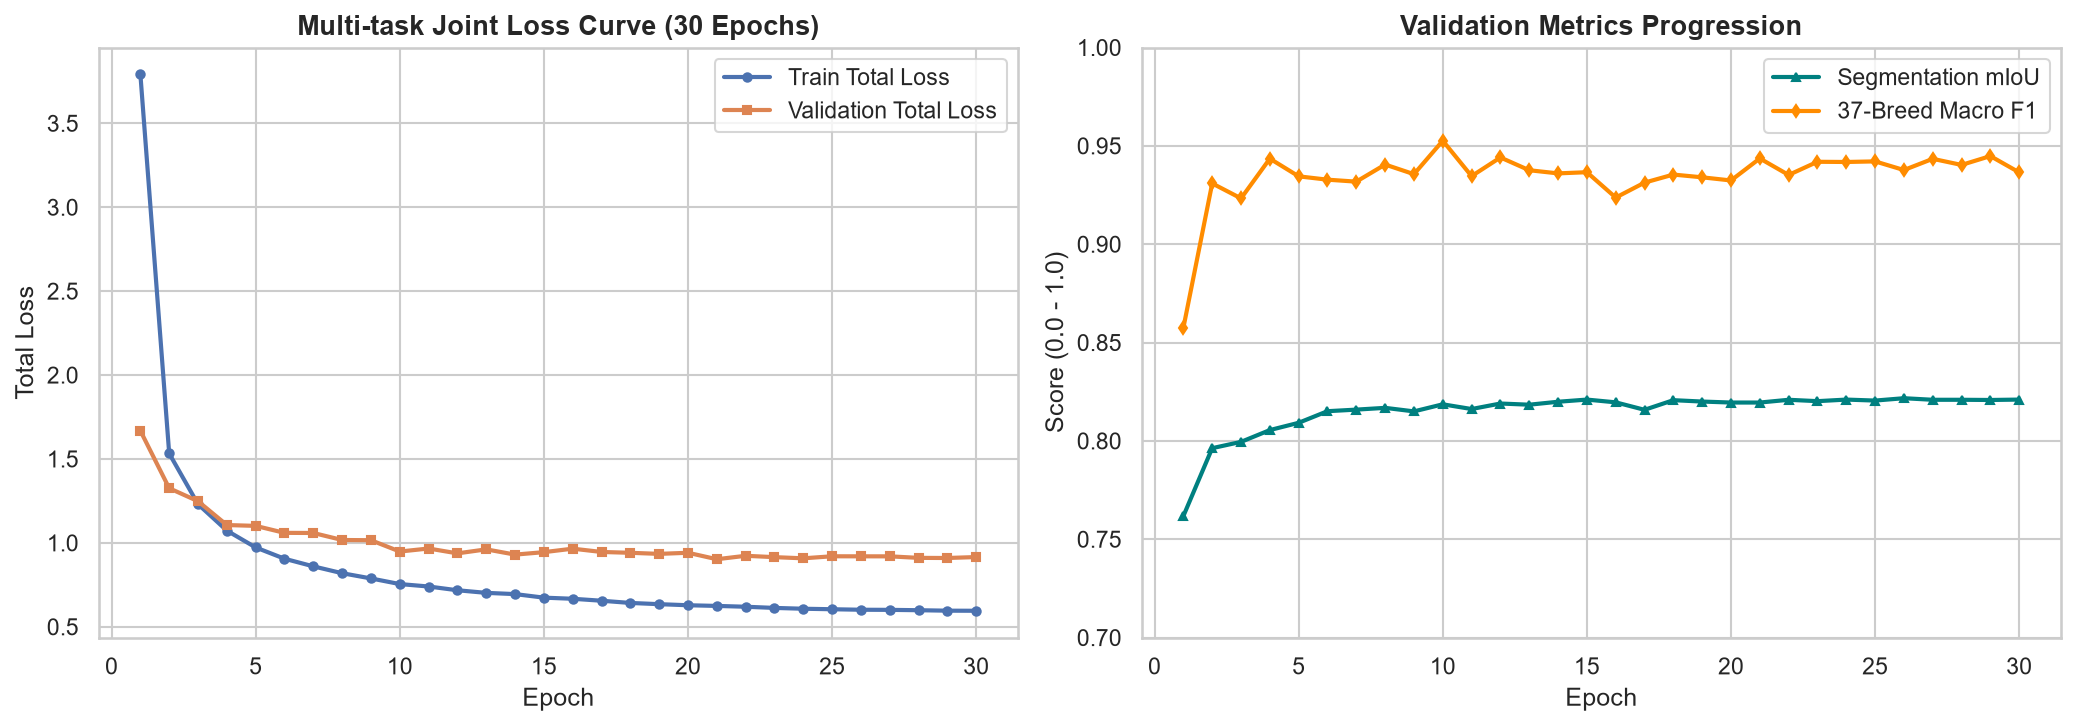

In [4]:
# เซลล์ที่ 4: พล็อตกราฟ Learning Curves 30 Epochs ของโมเดล Balanced
# หมายเหตุ: train.py แสดงผลแต่ละ epoch ทางหน้าจอแต่ไม่บันทึกลงไฟล์ ค่าด้านล่างจึงคัดลอกจาก log การเทรน
# (Train loss คำนวณขณะมี Augmentation/Dropout จึงเทียบระดับกับ Val loss ตรง ๆ ไม่ได้ ให้ดูแนวโน้ม)
epochs = list(range(1, 31))
train_losses = [
    3.7919, 1.5326, 1.2304, 1.0731, 0.9728, 0.9056, 0.8602, 0.8193, 0.7882, 0.7546,
    0.7401, 0.7177, 0.7022, 0.6948, 0.6737, 0.6670, 0.6553, 0.6421, 0.6348, 0.6284,
    0.6244, 0.6195, 0.6125, 0.6076, 0.6046, 0.6016, 0.6009, 0.5988, 0.5960, 0.5955
]
val_losses = [
    1.6681, 1.3256, 1.2482, 1.1063, 1.1013, 1.0597, 1.0590, 1.0172, 1.0159, 0.9484,
    0.9665, 0.9375, 0.9614, 0.9301, 0.9447, 0.9655, 0.9459, 0.9409, 0.9345, 0.9411,
    0.9026, 0.9231, 0.9150, 0.9080, 0.9202, 0.9199, 0.9198, 0.9107, 0.9099, 0.9156
]
val_miou = [
    0.7618, 0.7963, 0.7995, 0.8055, 0.8092, 0.8151, 0.8159, 0.8168, 0.8150, 0.8186,
    0.8162, 0.8190, 0.8184, 0.8199, 0.8210, 0.8196, 0.8158, 0.8207, 0.8200, 0.8195,
    0.8195, 0.8209, 0.8202, 0.8210, 0.8205, 0.8217, 0.8209, 0.8209, 0.8208, 0.8210
]
val_breed_f1 = [
    0.8575, 0.9309, 0.9233, 0.9435, 0.9345, 0.9328, 0.9318, 0.9405, 0.9356, 0.9526,
    0.9346, 0.9441, 0.9376, 0.9360, 0.9366, 0.9237, 0.9313, 0.9354, 0.9340, 0.9324,
    0.9436, 0.9352, 0.9419, 0.9418, 0.9421, 0.9377, 0.9434, 0.9403, 0.9448, 0.9365
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# กราฟที่ 1: Train vs Validation Loss
axes[0].plot(epochs, train_losses, label="Train Total Loss", marker="o", markersize=4, linewidth=2)
axes[0].plot(epochs, val_losses, label="Validation Total Loss", marker="s", markersize=4, linewidth=2)
axes[0].set_title("Multi-task Joint Loss Curve (30 Epochs)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Total Loss")
axes[0].legend()

# กราฟที่ 2: Validation Metrics Progression
axes[1].plot(epochs, val_miou, label="Segmentation mIoU", color="teal", marker="^", markersize=4, linewidth=2)
axes[1].plot(epochs, val_breed_f1, label="37-Breed Macro F1", color="darkorange", marker="d", markersize=4, linewidth=2)
axes[1].set_title("Validation Metrics Progression", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score (0.0 - 1.0)")
axes[1].set_ylim(0.70, 1.0)
axes[1].legend()

plt.tight_layout()
plt.savefig(os.path.join(cfg.OUTPUT_DIR, "slide_learning_curves.png"), dpi=300)
plt.show()

In [5]:
# เซลล์ที่ 5: โหลดโมเดลที่ดีที่สุด (Best Checkpoint) มาประเมินผลบน Unseen Test Set (3,669 ภาพ)
checkpoint_path = os.path.join(cfg.CHECKPOINT_DIR, f"best_model_{cfg.BACKBONE}.pth")

if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=cfg.DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    print(f"[+] โหลดน้ำหนักโมเดลสำเร็จจาก: {checkpoint_path} (Best Epoch: {checkpoint.get('epoch', 'N/A')})")

    # ค่า Hyperparameter ที่ใช้เทรนจริง (อ่านจาก config ที่ train.py บันทึกไว้ใน checkpoint)
    ck_cfg = checkpoint.get("config", cfg)
    hp_keys = ["BACKBONE", "IMAGE_SIZE", "BATCH_SIZE", "EPOCHS", "LEARNING_RATE", "WEIGHT_DECAY",
               "LABEL_SMOOTHING", "WEIGHT_SEG", "WEIGHT_BREED", "WEIGHT_SPECIES", "TRAIN_VAL_SPLIT_RATIO", "SEED"]
    hp_table = pd.DataFrame({"Hyperparameter": hp_keys, "ค่าที่ใช้เทรนจริง": [str(getattr(ck_cfg, k, "-")) for k in hp_keys]})
    display(hp_table)

    all_pred_masks, all_target_masks = [], []
    all_pred_breeds, all_target_breeds = [], []
    all_pred_species, all_target_species = [], []

    with torch.no_grad():
        for batch in test_loader:
            images = batch["image"].to(cfg.DEVICE)
            masks = batch["mask"].to(cfg.DEVICE)
            breeds = batch["breed"].to(cfg.DEVICE)
            species = batch["species"].to(cfg.DEVICE)

            preds = model(images)

            pred_seg = torch.argmax(preds["seg_logits"], dim=1).cpu().numpy()
            all_pred_masks.append(pred_seg)
            all_target_masks.append(masks.cpu().numpy())

            pred_breed = torch.argmax(preds["breed_logits"], dim=1).cpu().numpy()
            all_pred_breeds.extend(pred_breed.tolist())
            all_target_breeds.extend(breeds.cpu().numpy().tolist())

            pred_spec = torch.argmax(preds["species_logits"], dim=1).cpu().numpy()
            all_pred_species.extend(pred_spec.tolist())
            all_target_species.extend(species.cpu().numpy().tolist())

    seg_res = compute_segmentation_metrics(np.concatenate(all_pred_masks), np.concatenate(all_target_masks))
    breed_res = compute_classification_metrics(all_target_breeds, all_pred_breeds)
    species_res = compute_classification_metrics(all_target_species, all_pred_species)

    # แสดงตารางสรุปผลการประเมินแยกตามงาน (สำหรับนำไปวางในสไลด์)
    from sklearn.metrics import precision_recall_fscore_support
    sp_p, sp_r, sp_f, sp_n = precision_recall_fscore_support(all_target_species, all_pred_species, labels=[0, 1], zero_division=0)
    fmt = lambda v: f"{v:.4f} ({v*100:.2f}%)"
    SEG = "1. Image Segmentation (3-Class Trimap)"
    BRD = "2. Fine-grained Breed Classification (37 Classes)"
    SPC = "3. Species Classification (Cat vs Dog)"
    rows = [
        (SEG, "Mean IoU (mIoU)", seg_res["mIoU"]),
        (SEG, "Mean Dice Score", seg_res["mean_dice"]),
        (SEG, "IoU — Background", seg_res["iou_per_class"][0]),
        (SEG, "IoU — Pet", seg_res["iou_per_class"][1]),
        (SEG, "IoU — Boundary", seg_res["iou_per_class"][2]),
        (BRD, "Accuracy", breed_res["accuracy"]),
        (BRD, "Macro F1-Score", breed_res["f1_macro"]),
        (BRD, "Macro Precision", breed_res["precision_macro"]),
        (BRD, "Macro Recall", breed_res["recall_macro"]),
        (SPC, "Accuracy", species_res["accuracy"]),
        (SPC, "Macro F1-Score", species_res["f1_macro"]),
        (SPC, "Macro Precision", species_res["precision_macro"]),
        (SPC, "Macro Recall", species_res["recall_macro"]),
    ]
    summary_table = pd.DataFrame({
        "งาน (Task)": [r[0] for r in rows],
        "ตัวชี้วัด (Metric)": [r[1] for r in rows],
        "ผลลัพธ์บน Unseen Test Set": [fmt(r[2]) for r in rows],
    })
    display(summary_table)

    # Species แยกรายคลาส (ข้อมูลแมว:สุนัข ประมาณ 1:2 จึงควรดูแยก)
    species_table = pd.DataFrame({
        "Class": ["Cat", "Dog"],
        "Precision": [fmt(v) for v in sp_p], "Recall": [fmt(v) for v in sp_r],
        "F1-Score": [fmt(v) for v in sp_f], "จำนวนภาพ (Support)": sp_n,
    })
    display(species_table)
else:
    print(f"[!] ยังไม่พบไฟล์ {checkpoint_path} กรุณารัน train.py ก่อน")

[+] โหลดน้ำหนักโมเดลสำเร็จจาก: ./checkpoints\best_model_resnet50.pth (Best Epoch: 10)


,Hyperparameter,ค่าที่ใช้เทรนจริง
0,BACKBONE,resnet50
1,IMAGE_SIZE,224
2,BATCH_SIZE,32
3,EPOCHS,30
4,LEARNING_RATE,0.0001
5,WEIGHT_DECAY,0.0001
6,LABEL_SMOOTHING,0.05
7,WEIGHT_SEG,1.0
8,WEIGHT_BREED,1.0
9,WEIGHT_SPECIES,0.5


,งาน (Task),ตัวชี้วัด (Metric),ผลลัพธ์บน Unseen Test Set
0,1. Image Segmentation (3-Class Trimap),Mean IoU (mIoU),0.8266 (82.66%)
1,1. Image Segmentation (3-Class Trimap),Mean Dice Score,0.8987 (89.87%)
2,1. Image Segmentation (3-Class Trimap),IoU — Background,0.9466 (94.66%)
3,1. Image Segmentation (3-Class Trimap),IoU — Pet,0.8964 (89.64%)
4,1. Image Segmentation (3-Class Trimap),IoU — Boundary,0.6368 (63.68%)
5,2. Fine-grained Breed Classification (37 Classes),Accuracy,0.9169 (91.69%)
6,2. Fine-grained Breed Classification (37 Classes),Macro F1-Score,0.9154 (91.54%)
7,2. Fine-grained Breed Classification (37 Classes),Macro Precision,0.9188 (91.88%)
8,2. Fine-grained Breed Classification (37 Classes),Macro Recall,0.9165 (91.65%)
9,3. Species Classification (Cat vs Dog),Accuracy,0.9951 (99.51%)


,Class,Precision,Recall,F1-Score,จำนวนภาพ (Support)
0,Cat,0.9983 (99.83%),0.9865 (98.65%),0.9923 (99.23%),1183
1,Dog,0.9936 (99.36%),0.9992 (99.92%),0.9964 (99.64%),2486


In [6]:
# เซลล์ที่ 6: ตารางเปรียบเทียบ Multi-task ResNet-50 ทั้ง 3 รูปแบบ (ปรับน้ำหนัก Loss)
# - ค่าของแต่ละรูปแบบได้จากการรัน evaluate.py กับ checkpoint ของรูปแบบนั้นบน Unseen Test Set
# - ใช้ "รายงานผลและวิเคราะห์ Trade-off" เท่านั้น ไม่ได้ใช้ตารางนี้เลือกโมเดล
#   (Balanced เป็นการตั้งค่าหลักตั้งแต่ต้น และ checkpoint ของแต่ละรูปแบบถูกเลือกด้วย Validation Set ระหว่างเทรน)
comparison_df = pd.DataFrame({
    "รูปแบบการทดลอง (Multi-task Variant)": [
        "รูปแบบที่ 1: Seg-focused (เน้นงานตัดขอบภาพ)",
        "รูปแบบที่ 2: Cls-focused (เน้นงานจำแนกสายพันธุ์)",
        "รูปแบบที่ 3: Balanced (การตั้งค่าหลัก)"
    ],
    "สัดส่วนน้ำหนัก Loss (λ_seg : λ_breed : λ_species)": ["2.0 : 0.5 : 0.5", "0.5 : 2.0 : 0.5", "1.0 : 1.0 : 0.5"],
    "Seg mIoU": [0.8285, 0.8094, 0.8266],
    "Seg Mean Dice": [0.8998, 0.8862, 0.8987],
    "37-Breed Macro F1": [0.8942, 0.9168, 0.9154],
    "37-Breed Accuracy": [0.8965, 0.9182, 0.9169],
    "Species Macro F1": [0.9932, 0.9948, 0.9944],
})
display(comparison_df)

# ตรวจสอบว่าแถว Balanced ตรงกับผลที่คำนวณจริงในเซลล์ที่ 5
if "seg_res" in locals():
    computed = [seg_res["mIoU"], seg_res["mean_dice"], breed_res["f1_macro"], breed_res["accuracy"], species_res["f1_macro"]]
    recorded = comparison_df.iloc[2, 2:].astype(float).tolist()
    ok = all(abs(a - b) < 6e-4 for a, b in zip(computed, recorded))
    print("✅ แถว Balanced ตรงกับผลที่คำนวณจริงจาก checkpoint" if ok else
          f"[!] แถว Balanced ไม่ตรงกับผลที่คำนวณจริง: {[round(c, 4) for c in computed]} — ควรอัปเดตตาราง")

# วิเคราะห์ Trade-off เทียบกับ Balanced
base = comparison_df.iloc[2]
for i in (0, 1):
    r = comparison_df.iloc[i]
    print(f"{r.iloc[0].split(':')[1].strip():40s} | Δ mIoU = {r['Seg mIoU'] - base['Seg mIoU']:+.4f} | "
          f"Δ Breed F1 = {r['37-Breed Macro F1'] - base['37-Breed Macro F1']:+.4f}")


,รูปแบบการทดลอง (Multi-task Variant),สัดส่วนน้ำหนัก Loss (λ_seg : λ_breed : λ_species),Seg mIoU,Seg Mean Dice,37-Breed Macro F1,37-Breed Accuracy,Species Macro F1
0,รูปแบบที่ 1: Seg-focused (เน้นงานตัดขอบภาพ),2.0 : 0.5 : 0.5,0.8285,0.8998,0.8942,0.8965,0.9932
1,รูปแบบที่ 2: Cls-focused (เน้นงานจำแนกสายพันธุ์),0.5 : 2.0 : 0.5,0.8094,0.8862,0.9168,0.9182,0.9948
2,รูปแบบที่ 3: Balanced (การตั้งค่าหลัก),1.0 : 1.0 : 0.5,0.8266,0.8987,0.9154,0.9169,0.9944


✅ แถว Balanced ตรงกับผลที่คำนวณจริงจาก checkpoint
Seg-focused (เน้นงานตัดขอบภาพ)           | Δ mIoU = +0.0019 | Δ Breed F1 = -0.0212
Cls-focused (เน้นงานจำแนกสายพันธุ์)      | Δ mIoU = -0.0172 | Δ Breed F1 = +0.0014


---
## ส่วนที่ 4: การวิเคราะห์ผลลัพธ์เชิงลึก ตัวอย่างที่ถูก/ผิด และข้อจำกัด (Error Analysis & Limitations)
*(เนื้อหาสำคัญสำหรับสไลด์แผ่นที่ 10 - 12 เพื่อเก็บคะแนนเต็มหมวดวิเคราะห์ผล 2 คะแนน)*

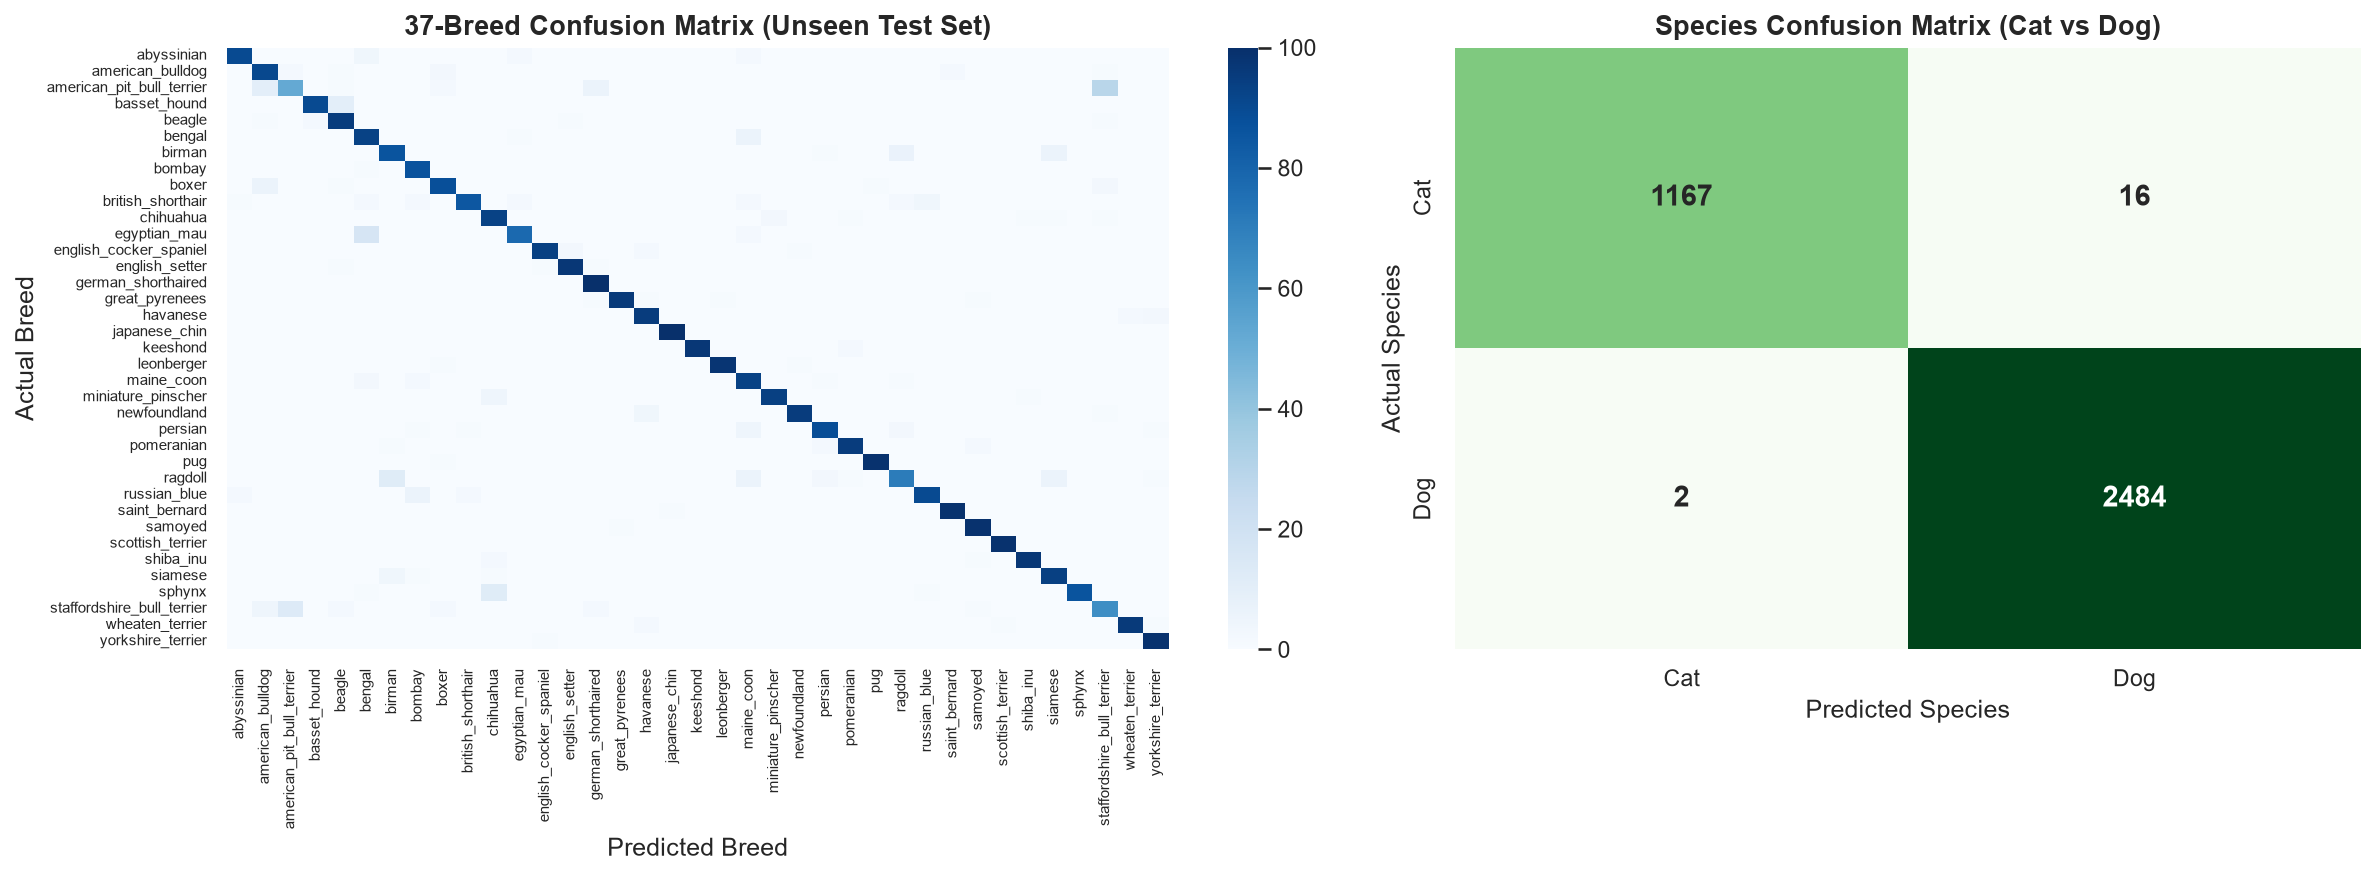


[!] 5 อันดับคู่สายพันธุ์ที่โมเดลทำนายสับสนมากที่สุด (นำไปใช้อธิบาย Error Analysis ในสไลด์):


,สายพันธุ์จริง (Actual Breed),สายพันธุ์ที่ทำนายผิด (Predicted as),จำนวนภาพที่ผิด (Count)
0,american_pit_bull_terrier,staffordshire_bull_terrier,29
1,egyptian_mau,bengal,17
2,staffordshire_bull_terrier,american_pit_bull_terrier,13
3,sphynx,chihuahua,12
4,ragdoll,birman,12


In [7]:
# เซลล์ที่ 7: แสดง Confusion Matrix และวิเคราะห์คู่สายพันธุ์ที่โมเดลสับสนมากที่สุด (Top Confused Pairs)
if 'breed_res' in locals():
    cm = breed_res["confusion_matrix"]
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1.3, 1]})
    
    # 1. พล็อต 37-Breed Confusion Matrix
    sns.heatmap(cm, cmap="Blues", cbar=True, ax=axes[0],
                xticklabels=BREED_NAMES, yticklabels=BREED_NAMES)
    axes[0].set_title("37-Breed Confusion Matrix (Unseen Test Set)", fontsize=13, fontweight="bold")
    axes[0].set_xlabel("Predicted Breed")
    axes[0].set_ylabel("Actual Breed")
    axes[0].tick_params(axis='both', which='major', labelsize=7)
    
    # 2. พล็อต Species Confusion Matrix
    sns.heatmap(species_res["confusion_matrix"], annot=True, fmt="d", cmap="Greens", cbar=False, ax=axes[1],
                xticklabels=["Cat", "Dog"], yticklabels=["Cat", "Dog"], annot_kws={"size": 14, "weight": "bold"})
    axes[1].set_title("Species Confusion Matrix (Cat vs Dog)", fontsize=13, fontweight="bold")
    axes[1].set_xlabel("Predicted Species")
    axes[1].set_ylabel("Actual Species")
    
    plt.tight_layout()
    plt.savefig(os.path.join(cfg.OUTPUT_DIR, "slide_confusion_matrices.png"), dpi=300)
    plt.show()

    # ค้นหา 5 อันดับคู่สายพันธุ์ที่โมเดลทำนายสลับกันมากที่สุด (สำหรับเขียนอธิบาย Error Analysis ในสไลด์)
    cm_no_diag = cm.copy()
    np.fill_diagonal(cm_no_diag, 0)
    flat_indices = np.argsort(cm_no_diag.ravel())[::-1][:5]
    
    error_pairs = []
    for idx in flat_indices:
        true_c, pred_c = np.unravel_index(idx, cm_no_diag.shape)
        error_pairs.append({
            "สายพันธุ์จริง (Actual Breed)": BREED_NAMES[true_c],
            "สายพันธุ์ที่ทำนายผิด (Predicted as)": BREED_NAMES[pred_c],
            "จำนวนภาพที่ผิด (Count)": int(cm_no_diag[true_c, pred_c])
        })
    print("\n[!] 5 อันดับคู่สายพันธุ์ที่โมเดลทำนายสับสนมากที่สุด (นำไปใช้อธิบาย Error Analysis ในสไลด์):")
    display(pd.DataFrame(error_pairs))

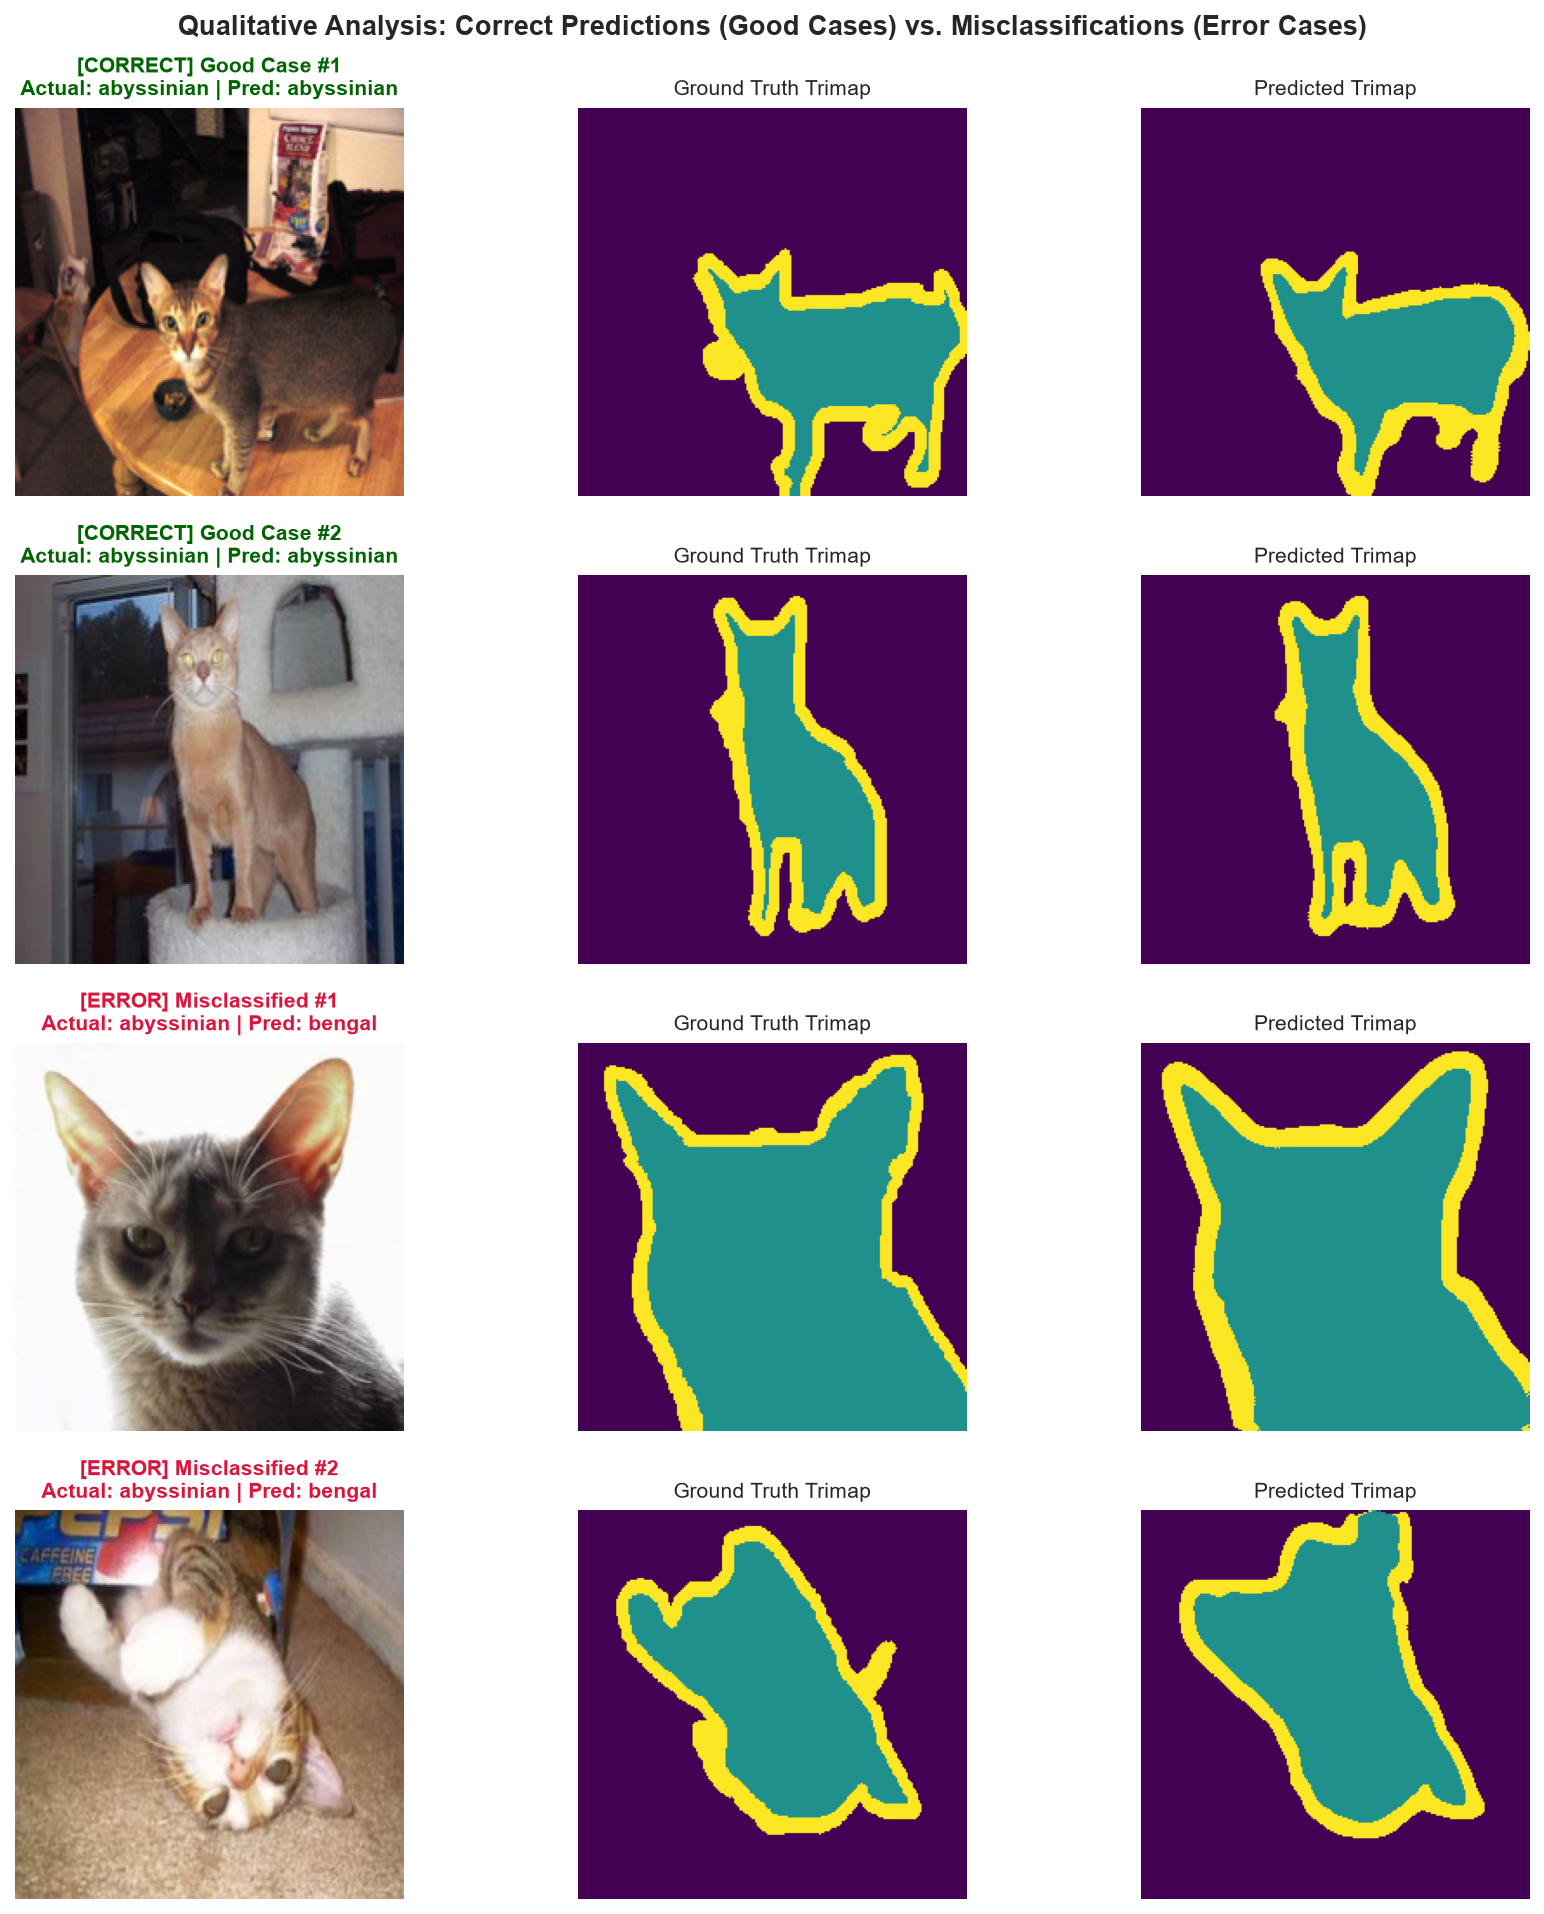

In [8]:
# เซลล์ที่ 8: แสดงภาพตัวอย่างเปรียบเทียบเคสที่ทำนายถูกต้องชัดเจน (Good Cases) และเคสที่ทำนายผิดพลาด (Error Cases)
if os.path.exists(checkpoint_path):
    good_cases = []
    error_cases = []

    with torch.no_grad():
        for batch in test_loader:
            images = batch["image"].to(cfg.DEVICE)
            masks = batch["mask"].to(cfg.DEVICE)
            breeds = batch["breed"].to(cfg.DEVICE)
            preds = model(images)
            
            pred_seg = torch.argmax(preds["seg_logits"], dim=1)
            pred_breeds = torch.argmax(preds["breed_logits"], dim=1)
            
            for i in range(images.size(0)):
                item = (
                    images[i].cpu(),
                    masks[i].cpu(),
                    pred_seg[i].cpu(),
                    breeds[i].item(),
                    pred_breeds[i].item()
                )
                if breeds[i].item() == pred_breeds[i].item() and len(good_cases) < 2:
                    good_cases.append(item)
                elif breeds[i].item() != pred_breeds[i].item() and len(error_cases) < 2:
                    error_cases.append(item)
            if len(good_cases) >= 2 and len(error_cases) >= 2:
                break

    # ใช้ข้อความแทน Emoji และใช้ภาษาอังกฤษบนหัวกราฟเพื่อป้องกันปัญหา Missing Glyph
    cases = good_cases + error_cases
    titles = ["[CORRECT] Good Case #1", "[CORRECT] Good Case #2", "[ERROR] Misclassified #1", "[ERROR] Misclassified #2"]
    title_colors = ["darkgreen", "darkgreen", "crimson", "crimson"]

    fig, axes = plt.subplots(4, 3, figsize=(12, 13))
    for row, (img_t, gt_m, pred_m, true_b, pred_b) in enumerate(cases):
        img = np.clip(img_t.permute(1, 2, 0).numpy() * std + mean, 0, 1)
        
        axes[row, 0].imshow(img)
        axes[row, 0].set_title(
            f"{titles[row]}\nActual: {BREED_NAMES[true_b]} | Pred: {BREED_NAMES[pred_b]}",
            fontsize=10, fontweight="bold", color=title_colors[row]
        )
        axes[row, 0].axis("off")
        
        axes[row, 1].imshow(gt_m.numpy(), cmap="viridis", vmin=0, vmax=2)
        axes[row, 1].set_title("Ground Truth Trimap", fontsize=10)
        axes[row, 1].axis("off")
        
        axes[row, 2].imshow(pred_m.numpy(), cmap="viridis", vmin=0, vmax=2)
        axes[row, 2].set_title("Predicted Trimap", fontsize=10)
        axes[row, 2].axis("off")

    plt.suptitle("Qualitative Analysis: Correct Predictions (Good Cases) vs. Misclassifications (Error Cases)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(os.path.join(cfg.OUTPUT_DIR, "slide_good_vs_error_cases.png"), dpi=300)
    plt.show()

### 4.1 สรุปการวิเคราะห์ข้อผิดพลาดและข้อจำกัดของแบบจำลอง (สำหรับใส่สไลด์แผ่นวิเคราะห์ผล)

1. **ข้อผิดพลาดในงาน Classification (Inter-class Similarity):**
   * ข้อผิดพลาดส่วนใหญ่ไม่ได้เกิดจากการแยกแมวกับสุนัข (Species Accuracy **99.51%**) แต่เกิดกับ **สายพันธุ์ที่หน้าตาใกล้เคียงกัน** ตามตาราง Top Confused Pairs ในเซลล์ที่ 7:
     - *American Pit Bull Terrier* → *Staffordshire Bull Terrier* (29 ภาพ) และกลับกัน (13 ภาพ): โครงหน้าและรูปร่างคล้ายกันมาก
     - *Egyptian Mau* → *Bengal* (17 ภาพ): แมวขนลายจุดทั้งคู่
     - *Ragdoll* → *Birman* (12 ภาพ): แมวขนยาวแต้มสีคล้ายกัน
   * **ข้อผิดพลาดข้ามสปีชีส์:** *Sphynx* (แมว) ถูกทำนายเป็น *Chihuahua* (สุนัข) 12 ภาพ ทั้งที่ Species Head ทำนายแมวผิดรวมเพียง 16 ภาพ แสดงว่า **Breed Head กับ Species Head ไม่ได้ถูกบังคับให้สอดคล้องกัน**
2. **ข้อผิดพลาดในงาน Segmentation:**
   * ดูค่า IoU รายคลาสในเซลล์ที่ 5: คลาส Background และ Pet มี IoU สูง ส่วน **Boundary** ต่ำกว่าชัดเจน เพราะเป็นแถบแคบรอบตัวสัตว์และเป็นบริเวณที่ป้ายกำกับเองก็ไม่แน่นอน ซึ่งเป็นสาเหตุหลักที่ทำให้ mIoU (เฉลี่ย 3 คลาส) ต่ำกว่า Dice/Accuracy
   * ภาพที่ยากมักเป็นภาพที่ขนกลืนกับพื้นหลัง มีสิ่งกีดขวาง หรือเห็นสัตว์เพียงบางส่วน (ดูภาพในเซลล์ที่ 8)
3. **ผลของการปรับน้ำหนัก Loss (เซลล์ที่ 6):** Seg-focused ได้ mIoU สูงขึ้นเล็กน้อยแต่ Breed F1 ลดลงชัดเจน ส่วน Cls-focused ได้ Breed F1 ใกล้เคียง Balanced แต่ mIoU ลดลง → การเน้นงานหนึ่งแลกกับอีกงาน และ Balanced ให้ผลใกล้เคียงค่าที่ดีที่สุดของทั้งสองงานพร้อมกัน

### 4.2 ข้อจำกัด
* **ไม่มี Single-task baseline:** การทดลองเปรียบเทียบน้ำหนัก Loss ภายใน Multi-task จึง *ยังสรุปไม่ได้* ว่า Multi-task ดีกว่าการเทรนแต่ละงานแยกกัน
* **Closed-set:** โมเดลต้องตอบ 1 ใน 37 สายพันธุ์เสมอ เช่น ภาพสุนัข Akita (ไม่มีในชุดข้อมูล) ถูกทำนายเป็น *shiba_inu* ด้วยความมั่นใจ 97.64% — ความมั่นใจสูงไม่ได้แปลว่าถูก
* **ความละเอียด 224×224:** รายละเอียดขนและขอบเล็ก ๆ หายไป ทำให้คลาส Boundary ยาก
* **เทรนรูปแบบละ 1 ครั้ง (1 seed):** ความต่างเล็กน้อยระหว่างรูปแบบ (เช่น mIoU ต่างกัน 0.002) อาจอยู่ในช่วงความแปรปรวนของการสุ่ม
* **Validation เล็ก (ประมาณ 20 ภาพต่อสายพันธุ์):** Breed F1 บน Validation แกว่งระหว่าง epoch การเลือก checkpoint จึงมีความไม่แน่นอน

### 4.3 แนวทางพัฒนาต่อ
* เทรน Single-task baseline (Segmentation อย่างเดียว / Classification อย่างเดียว) ด้วยการตั้งค่าเดียวกัน เพื่อวัดประโยชน์ของ Multi-task โดยตรง
* ปรับน้ำหนัก Loss อัตโนมัติ (เช่น Uncertainty Weighting) แทนการกำหนดเอง
* เพิ่มขนาดภาพเป็น 384×384 หรือใช้ Boundary-aware Loss เพื่อให้ขอบคมขึ้น
* อนุมาน Species จาก Breed หรือเพิ่ม Consistency Loss ให้ทั้งสองหัวสอดคล้องกัน
* เพิ่มการตรวจจับภาพนอกคลาส (เช่น ตั้ง threshold ความมั่นใจ)


---
## ส่วนที่ 5: โครงร่างสไลด์นำเสนอ 10 แผ่น (Slide Deck Blueprint)
*(ไกด์ไลน์สำหรับทีมทำสไลด์ เพื่อให้ครอบคลุมรูบริก 15 คะแนนเต็มและนำเสนอทันเวลา)*

| แผ่นที่ | หัวข้อสไลด์ (Slide Title) | เนื้อหาสำคัญที่ต้องใส่ | รูปภาพ/ตารางที่ดึงจาก Notebook นี้ |
| :---: | :--- | :--- | :--- |
| **1** | **Title & Team Members** | ชื่อโปรเจกต์ Multi-task Learning on Oxford-IIIT Pet Dataset และรายชื่อสมาชิก **พร้อมหน้าที่รับผิดชอบของแต่ละคน** (เกณฑ์การนำเสนอระดับดีมากต้องอธิบายงานที่รับผิดชอบได้) | - |
| **2** | **Problem Statement & Objectives** | ทำไมต้องทำ Multi-task? (ใช้ Encoder ร่วมกันแทนการสร้างหลายโมเดล) + วัตถุประสงค์ 3 ข้อในส่วนที่ 1.1 | แผนภาพ Pipeline หลายโมเดล vs Shared Encoder |
| **3** | **Dataset & Leakage Prevention** | แหล่งที่มา Oxford VGG (7,349 ภาพ, 37 สายพันธุ์) + ตารางแบ่ง Train/Val/Test + การป้องกัน Data Leakage | ตาราง `split_df` + รูป `slide_dataset_samples.png` |
| **4** | **Multi-task Architecture** | โครงสร้าง Shared ResNet Backbone + U-Net Decoder (Skip Connections) + 2 Classification Heads | แผนภาพ Architecture + ตาราง `param_df` |
| **5** | **Joint Loss & Training Setup** | สมการ $\mathcal{L}_{total}$ (CE + Dice + Label Smoothing) + การตั้งค่า AdamW, Cosine LR, bfloat16, Batch 32 | สมการในส่วนที่ 2.2 + ตาราง `hp_table` (เซลล์ที่ 5) |
| **6** | **Experimental Comparison (3 รูปแบบ)** | เปรียบเทียบ Balanced / Seg-focused / Cls-focused ที่ต่างกันเพียงน้ำหนัก Loss + วิเคราะห์ Trade-off | ตาราง `comparison_df` และค่า Δ (เซลล์ที่ 6) |
| **7** | **Learning Curves & Convergence** | พฤติกรรมการเรียนรู้ 30 Epochs ไม่เกิด Overfitting และกราฟไต่ระดับของ mIoU / Macro F1 | รูป `slide_learning_curves.png` (เซลล์ที่ 4) |
| **8** | **Unseen Test Set Evaluation** | รายงานผลลัพธ์สุดท้ายบนชุดทดสอบ 3,669 ภาพ แยกตามงาน (mIoU 0.8266, Dice 0.8987, IoU รายคลาส, Breed F1 0.9154, Species Precision/Recall/F1) | ตาราง `summary_table` และ `species_table` (เซลล์ที่ 5) |
| **9** | **Confusion Matrix Analysis** | วิเคราะห์ Confusion Matrix ของ 37 สายพันธุ์ และคู่สายพันธุ์ที่สับสนมากที่สุด 5 อันดับแรก | รูป `slide_confusion_matrices.png` + ตาราง Top Confused Pairs |
| **10** | **Visual Results, Error Analysis & Conclusion** | ภาพ Good Cases vs Error Cases + ข้อจำกัดและแนวทางพัฒนาต่อ (ส่วนที่ 4.2–4.3) + ตัวอย่างภาพ Akita ที่ถูกทำนายเป็น shiba_inu + สรุปผล | รูป `slide_good_vs_error_cases.png` (เซลล์ที่ 8), `Inference 2.png` |